# CALC

In [23]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
N = 4


def W(n, N=4):
    return sp.E**(-2*sp.pi*sp.I*n/N)


# Term by term construction
'''
wMatrix = sp.Matrix([
    [W(0*0), W(0*1), W(0*2), W(0*3), W(0*4),W(0*5),W(0*6)],
    [W(1*0), W(1*1), W(1*2), W(1*3), W(1*4), W(1*5), W(1*6)],
    [W(2*0), W(2*1), W(2*2), W(2*3), W(2*4), W(2*5), W(2*6)],
    [W(3*0), W(3*1), W(3*2), W(3*3), W(3*4), W(3*5), W(3*6)],
    [W(4*0), W(4*1), W(4*2), W(4*3), W(4*4), W(4*5), W(4*6)],
    [W(5*0), W(5*1), W(5*2), W(5*3), W(5*4), W(5*5), W(5*6)],
    [W(6*0), W(6*1), W(6*2), W(6*3), W(6*4), W(6*5), W(6*6)]
])
'''
wMatrix = sp.Matrix([[W(i * j) for j in range(N)] for i in range(N)])

display(wMatrix)

Matrix([
[1,  1,  1,  1],
[1, -I, -1,  I],
[1, -1,  1, -1],
[1,  I, -1, -I]])

In [34]:
sp.N(W(9, 6))

-1.00000000000000

# Visualizador

In [13]:
"""
dft_visualizador.py
--------------------
Calcula la DFT con la matriz de kernel W_N^(nk) (X = W * x) y grafica:
    1) x[n] muestreada + señal original punteada
    2) Re{X[k]} e Im{X[k]}
    3) |X[k]|
    4) Fase

Uso:
    python3 dft_visualizador.py
"""

import os
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
PATH = "src/pyfig/"


In [14]:
def construir_matriz_dft(N: int,printable= False) -> np.ndarray:
    n = np.arange(N).reshape(-1, 1)
    k = np.arange(N).reshape(1, -1)
    W = np.exp(-2j    * np.pi * n * k / N)
    
    #W_eval = np.vectorize(sp.N)(W)
    
    if printable:
        print(f"Matriz DFT de tamaño {N}x{N}:")
        # print with 2 decimal places and omit imaginary part if it's very small and tab\t
        np.set_printoptions(precision=2, suppress=True)
        np.set_printoptions(formatter={'complexfloat': lambda x: f"{x.real:.2f}" if abs(x.imag) < 1e-9 else f"{x.real:.2f}+{x.imag:.2f}j\t"})
        np.set_printoptions(formatter={'float': lambda x: f"{x:.2f}"})
        print(W)
    return W



In [ ]:
# n=1;k=1;N=4
# n = np.arange(N).reshape(-1, 1)
# k = np.arange(N).reshape(1, -1)
# Wsp = sp.E**(-2* sp.I*sp.pi*n*k/N)
# Wnp = np.exp(-2j    * np.pi * n * k / N)
construir_matriz_dft(6, printable=True)


Matriz DFT de tamaño 6x6:
[[ 1. +0.j    1. +0.j    1. +0.j    1. +0.j    1. +0.j    1. +0.j  ]
 [ 1. +0.j    0.5-0.87j -0.5-0.87j -1. -0.j   -0.5+0.87j  0.5+0.87j]
 [ 1. +0.j   -0.5-0.87j -0.5+0.87j  1. +0.j   -0.5-0.87j -0.5+0.87j]
 [ 1. +0.j   -1. -0.j    1. +0.j   -1. -0.j    1. +0.j   -1. -0.j  ]
 [ 1. +0.j   -0.5+0.87j -0.5-0.87j  1. +0.j   -0.5+0.87j -0.5-0.87j]
 [ 1. +0.j    0.5+0.87j -0.5+0.87j -1. -0.j   -0.5-0.87j  0.5-0.87j]]


array([[ 1. +0.j  ,  1. +0.j  ,  1. +0.j  ,  1. +0.j  ,  1. +0.j  ,
         1. +0.j  ],
       [ 1. +0.j  ,  0.5-0.87j, -0.5-0.87j, -1. -0.j  , -0.5+0.87j,
         0.5+0.87j],
       [ 1. +0.j  , -0.5-0.87j, -0.5+0.87j,  1. +0.j  , -0.5-0.87j,
        -0.5+0.87j],
       [ 1. +0.j  , -1. -0.j  ,  1. +0.j  , -1. -0.j  ,  1. +0.j  ,
        -1. -0.j  ],
       [ 1. +0.j  , -0.5+0.87j, -0.5-0.87j,  1. +0.j  , -0.5+0.87j,
        -0.5-0.87j],
       [ 1. +0.j  ,  0.5+0.87j, -0.5+0.87j, -1. -0.j  , -0.5-0.87j,
         0.5-0.87j]])

In [39]:

def calcular_dft(x: np.ndarray) -> np.ndarray:
    return construir_matriz_dft(len(x)) @ x


def graficar_dft(x, titulo="Señal", nombre_archivo=None,
                 senal_original=None, t_original=None, fs=None):
    """
    senal_original : función f(t) o arreglo con la señal continua.
    t_original     : instantes (mismas unidades que el eje de x[n]).
    fs             : frecuencia de muestreo. Si se da, el eje del panel 1
                     es tiempo (n/fs) y la señal original debe ser f(t) en
                     segundos. Si es None, el eje es el índice n.
    """
    x = np.array(x, dtype=complex)
    N = len(x)
    n = np.arange(N)
    k = np.arange(N)

    # Eje horizontal del panel 1
    eje = n / fs if fs else n
    xlabel = "t (s)" if fs else "n (muestra)"

    # DFT con la matriz y verificación (ambas SIN normalizar)
    X_raw = calcular_dft(x)
    error = np.max(np.abs(X_raw - np.fft.fft(x)))
    print(f"[{titulo}] Error máximo vs numpy.fft: {error:.2e}")

    X = X_raw 
    magnitud = np.abs(X)
    fase = np.angle(X)
    fase_mostrar = np.where(magnitud > 1e-9, fase, 0.0)

    fig, axs = plt.subplots(2, 2, figsize=(11, 8))
    fig.suptitle(f"Análisis DFT (N={N}) — {titulo}", fontsize=14, fontweight="bold")

    # 1) Entrada muestreada + señal original punteada
    ax = axs[0, 0]
    if senal_original is not None:
        if callable(senal_original):
            if t_original is None:
                t_original = np.linspace(eje.min(), eje.max(), 1000)
            y_original = senal_original(np.asarray(t_original))
        else:
            y_original = np.asarray(senal_original)
            if t_original is None:
                t_original = np.linspace(eje.min(), eje.max(), len(y_original))
        ax.plot(t_original, np.real(y_original), linestyle=":", linewidth=2.5,
                color="C3", label="Original", zorder=1)

    ax.stem(eje, x.real, linefmt="C0-", markerfmt="C0o", basefmt="k-",
            label="Muestreada")
    ax.set_title("Entrada x[n]")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("x[n]")
    ax.grid(True, alpha=0.3)
    ax.legend()

    # 2) Re e Im
    ax = axs[0, 1]
    ancho = 0.35
    ax.bar(k - ancho / 2, X.real, width=ancho, label="Re{X[k]}")
    ax.bar(k + ancho / 2, X.imag, width=ancho, label="Im{X[k]}")
    ax.set_title("Parte real e imaginaria de X[k]")
    ax.set_xlabel("k")
    ax.set_ylabel("Valor")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.legend()
    ax.grid(True, alpha=0.3)

    # 3) Magnitud
    ax = axs[1, 0]
    ax.stem(k, magnitud)
    ax.set_title("Espectro de magnitud |X[k]|")
    ax.set_xlabel("k")
    ax.set_ylabel("|X[k]|")
    ax.grid(True, alpha=0.3)

    # 4) Fase
    ax = axs[1, 1]
    ax.stem(k, fase_mostrar)
    ax.set_title("Espectro de fase φ_k")
    ax.set_xlabel("k")
    ax.set_ylabel("Fase (rad)")
    ax.set_yticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
    ax.set_yticklabels(["-π", "-π/2", "0", "π/2", "π"])
    ax.grid(True, alpha=0.3)

    plt.tight_layout()

    if nombre_archivo:
        os.makedirs(PATH, exist_ok=True)
        path_to_save = PATH + nombre_archivo
        plt.savefig(path_to_save, dpi=150)
        print(f"Figura guardada en: {path_to_save}")

    return fig


def imprimir_resultados(x, titulo):
    """Imprime X[k] en forma rectangular y polar."""
    X = calcular_dft(np.array(x, dtype=complex))
    print(f"\n=== {titulo} ===")
    print(f"x[n] = {np.real_if_close(np.array(x))}")
    for k, Xk in enumerate(X):
        mag = np.abs(Xk)
        fase = np.angle(Xk)
        re = 0.0 if abs(Xk.real) < 1e-9 else Xk.real
        im = 0.0 if abs(Xk.imag) < 1e-9 else Xk.imag
        print(
            f"  X[{k}] = {re:+.4f} {im:+.4f}j   "
            f"| |X[{k}]| = {mag:.4f}   "
            f"∠ {fase:+.4f} rad ({np.degrees(fase):+.1f}°)"
        )

## Linea Continua


=== Linea_continua ===
x[n] = [3 3 3 3]
  X[0] = +12.0000 +0.0000j   | |X[0]| = 12.0000   ∠ +0.0000 rad (+0.0°)
  X[1] = +0.0000 +0.0000j   | |X[1]| = 0.0000   ∠ -2.3562 rad (-135.0°)
  X[2] = +0.0000 +0.0000j   | |X[2]| = 0.0000   ∠ -1.5708 rad (-90.0°)
  X[3] = +0.0000 +0.0000j   | |X[3]| = 0.0000   ∠ -0.7854 rad (-45.0°)
[Línea continua x[n]=3] Error máximo vs numpy.fft: 1.56e-15
Figura guardada en: src/pyfig/dft_Linea_continua.png


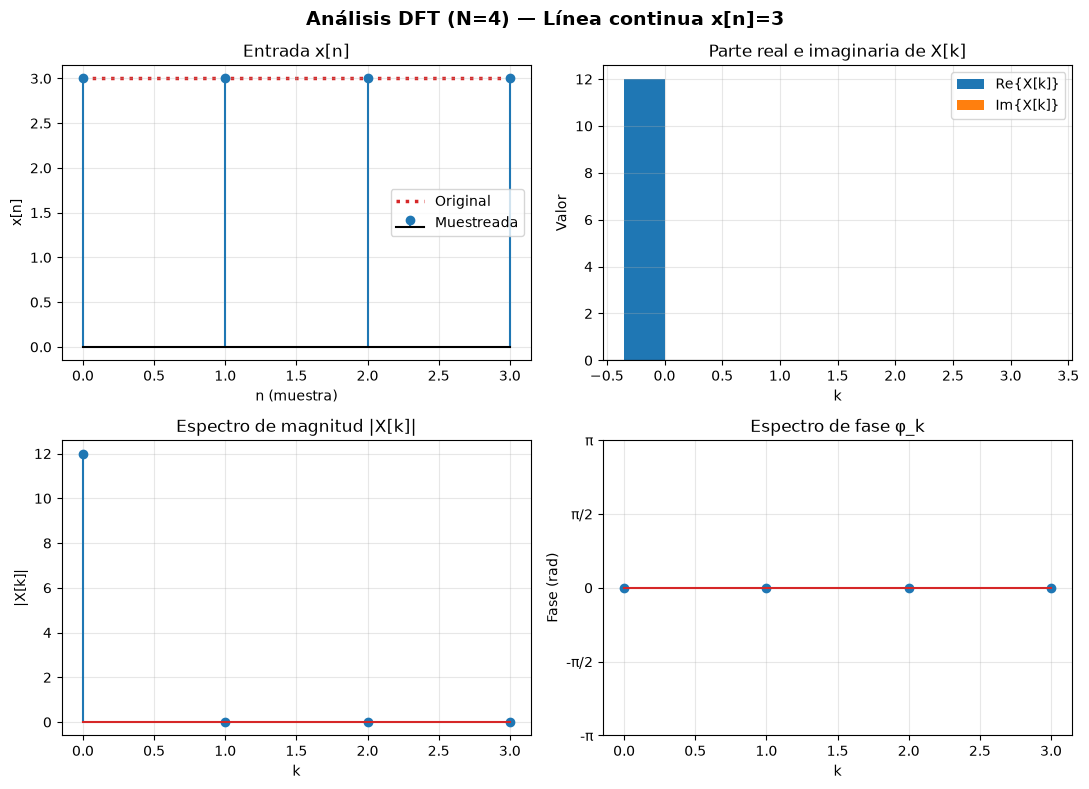

In [17]:
# ------------------------------------------------------------------
# Caso 1: Línea continua x[n] = 3, 3, 3, 3  (del documento)
# ------------------------------------------------------------------
x_continua = [3, 3, 3, 3]
string = "Linea_continua"
senal = lambda t: 3*np.ones_like(t)
imprimir_resultados(x_continua ,string)
graficar_dft(x_continua, titulo="Línea continua x[n]=3",
                nombre_archivo=f"dft_{string}.png",senal_original = senal)
plt.show()



## Senoidal


=== Senoidal ===
x[n] = [ 0  1  0 -1]
  X[0] = +0.0000 +0.0000j   | |X[0]| = 0.0000   ∠ +0.0000 rad (+0.0°)
  X[1] = +0.0000 -2.0000j   | |X[1]| = 2.0000   ∠ -1.5708 rad (-90.0°)
  X[2] = +0.0000 +0.0000j   | |X[2]| = 0.0000   ∠ +1.5708 rad (+90.0°)
  X[3] = +0.0000 +2.0000j   | |X[3]| = 2.0000   ∠ +1.5708 rad (+90.0°)
[Senoidal x[n]=[0,1,0,-1]] Error máximo vs numpy.fft: 7.35e-16
Figura guardada en: src/pyfig/dft_senoidal_4pts.png


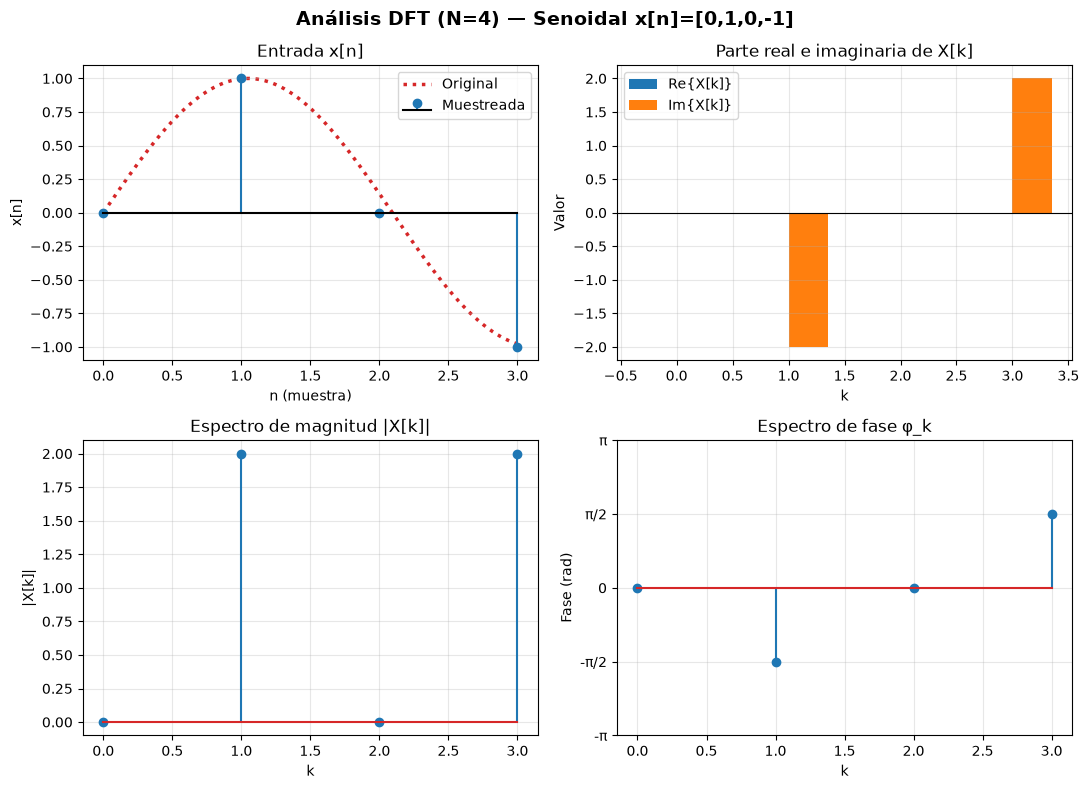

In [18]:
# ------------------------------------------------------------------
# Caso 2: Senoidal de 4 puntos x[n] = 0, 1, 0, -1  (del documento)
# ------------------------------------------------------------------
x_senoidal = [0, 1, 0, -1]
string = "Senoidal"
imprimir_resultados(x_senoidal, string)
graficar_dft(x_senoidal, titulo=f"{string} x[n]=[0,1,0,-1]",
                nombre_archivo="dft_senoidal_4pts.png", senal_original = lambda t: np.sin(1.5 * t))


plt.show()


=== Pulso Cuadrado de 4 puntos ===
x[n] = [0 3 3 0]
  X[0] = +6.0000 +0.0000j   | |X[0]| = 6.0000   ∠ +0.0000 rad (+0.0°)
  X[1] = -3.0000 -3.0000j   | |X[1]| = 4.2426   ∠ -2.3562 rad (-135.0°)
  X[2] = +0.0000 +0.0000j   | |X[2]| = 0.0000   ∠ +1.5708 rad (+90.0°)
  X[3] = -3.0000 +3.0000j   | |X[3]| = 4.2426   ∠ +2.3562 rad (+135.0°)
[Pulso Cuadrado x[n]=[0,3,3,0]] Error máximo vs numpy.fft: 9.93e-16
Figura guardada en: src/pyfig/dft_pulso_4pts.png


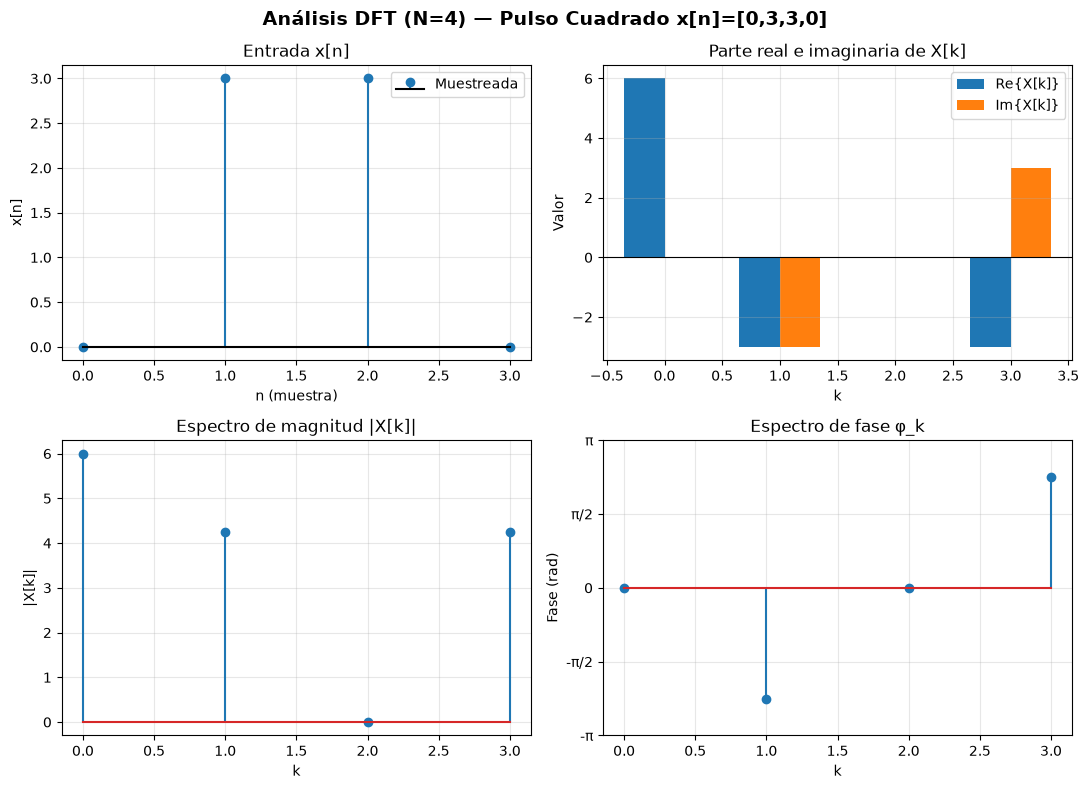

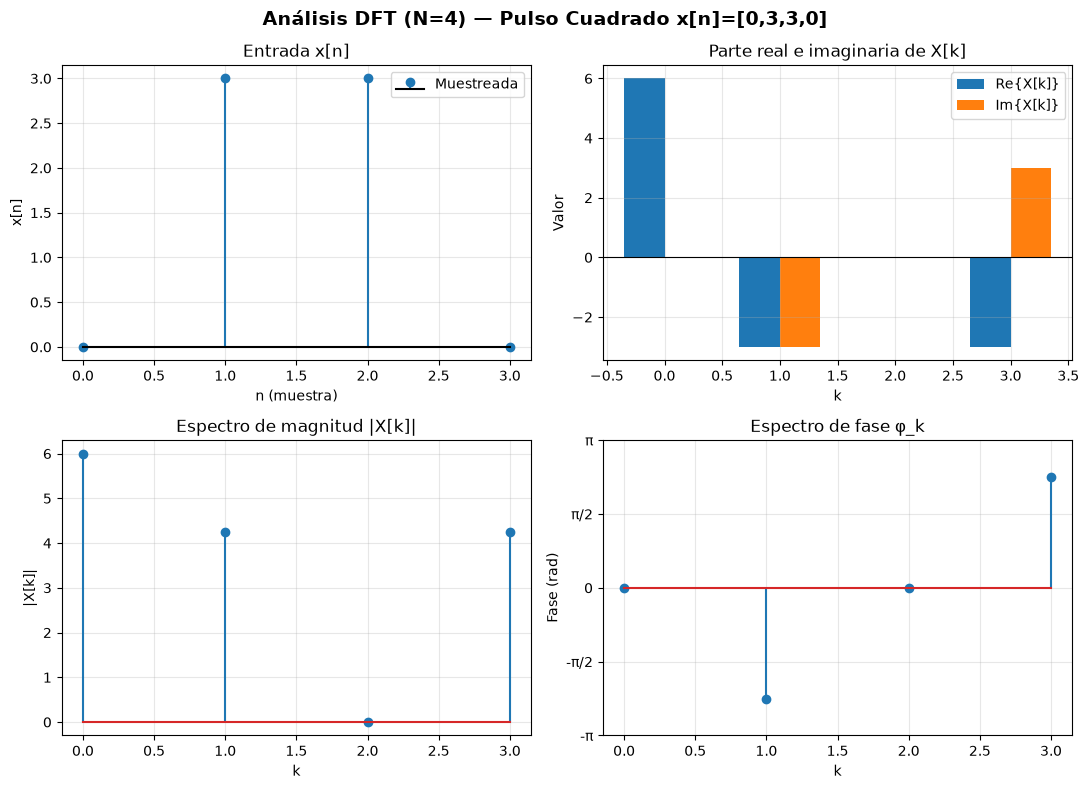

In [19]:
x =[0, 3, 3 ,0]
imprimir_resultados(x, "Pulso Cuadrado de 4 puntos")
graficar_dft(x, titulo="Pulso Cuadrado x[n]=[0,3,3,0]",
                nombre_archivo="dft_pulso_4pts.png")


## Senoidal 4 puntos

In [20]:
f1 = sin()

NameError: name 'sin' is not defined

In [ ]:
# ------------------------------------------------------------------
# Caso 2: Senoidal de 4 puntos x[n] = 0, 1, 0, -1  (del documento)
# ------------------------------------------------------------------
x_senoidal = [0, 1, 0, -1]
f = 1 # Hz
phi = 0  # fase inicial para la señal seno


phi2 = np.pi/4  # fase inicial para la señal coseno
w = 1.5

f1 = lambda t: np.sin(w*t+phi)
string = "Senoidal"
imprimir_resultados(x_senoidal, string)
graficar_dft(x_senoidal, titulo=f"{string} x[n]=[0,1,0,-1]",
                nombre_archivo="dft_senoidal_4pts.png", senal_original =  f1)


plt.show()


=== Senoidal ===
x[n] = [ 0  1  0 -1]
  X[0] = +0.0000 +0.0000j   | |X[0]| = 0.0000   ∠ +0.0000 rad (+0.0°)
  X[1] = +0.0000 -2.0000j   | |X[1]| = 2.0000   ∠ -1.5708 rad (-90.0°)
  X[2] = +0.0000 +0.0000j   | |X[2]| = 0.0000   ∠ +1.5708 rad (+90.0°)
  X[3] = +0.0000 +2.0000j   | |X[3]| = 2.0000   ∠ +1.5708 rad (+90.0°)
[Senoidal x[n]=[0,1,0,-1]] Error máximo vs numpy.fft: 7.35e-16
Figura guardada en: src/pyfig/dft_senoidal_4pts.png


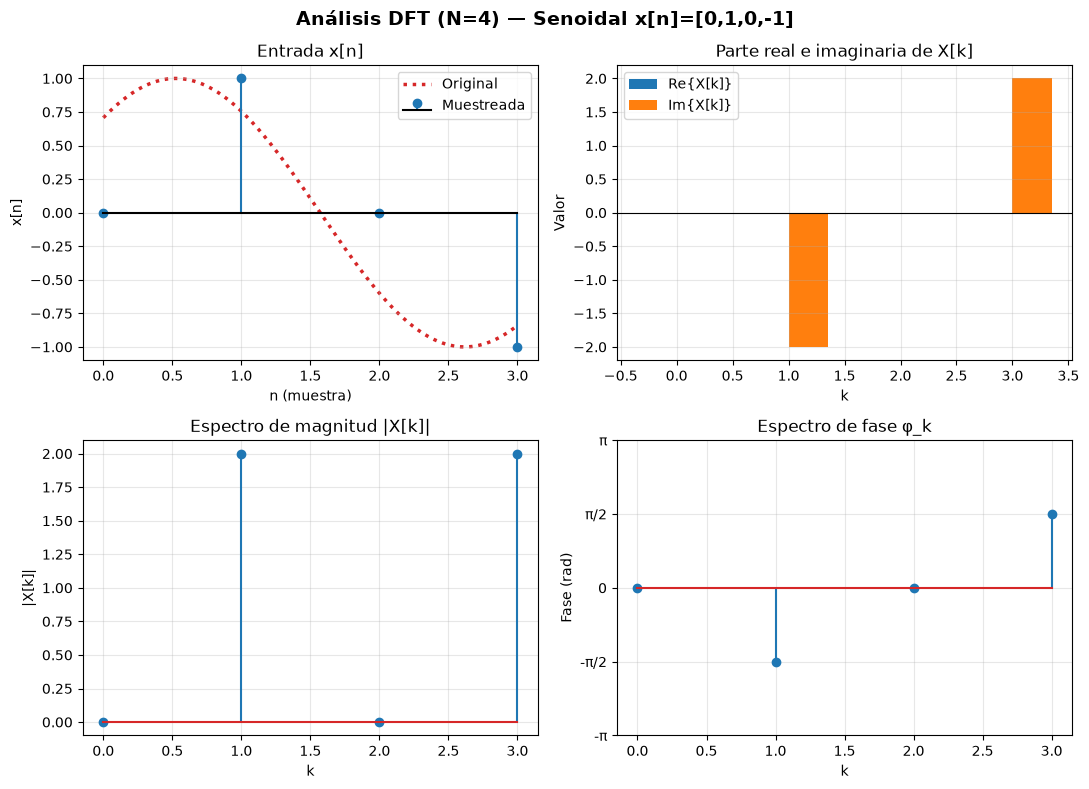

In [43]:
# ------------------------------------------------------------------
# Caso 2: Senoidal de 4 puntos x[n] = 0, 1, 0, -1  (del documento)
# ------------------------------------------------------------------
x_senoidal = [0, 1, 0, -1]
f = 1 # Hz
phi2 = 20

phi2 = np.pi/4  # fase inicial para la señal coseno
w = 1.5

f1 = lambda t: np.sin(w*t+phi2)
string = "Senoidal"
imprimir_resultados(x_senoidal, string)
graficar_dft(x_senoidal, titulo=f"{string} x[n]=[0,1,0,-1]",
                nombre_archivo="dft_senoidal_4pts.png", senal_original =  f1)


plt.show()

# Suma de senoidales

### Same Freq

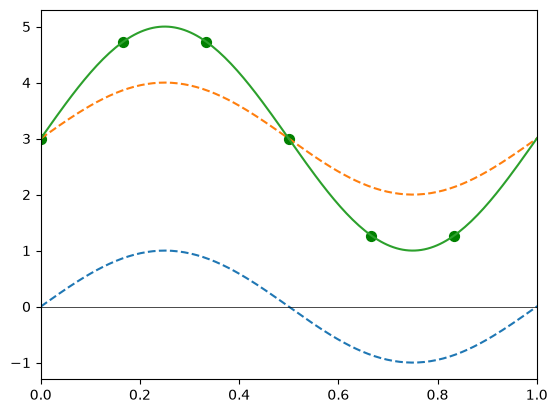

f(dots) = [3.00 4.73 4.73 3.00 1.27 1.27]


In [61]:
t = np.linspace(0, 2*np.pi, 1000)

N = 6
f1 = 1; f2 = 1
phi1 = 0
phi2 = 0#np.pi/2

w1 = 2 * np.pi * f1
w2 = 2 * np.pi * f2

def f1(t):
    return np.sin(w1*t+phi1)
def f2(t):
    return np.sin(w2*t+phi2)
def f3(t):
    return np.sin(w1*t+phi1) + np.sin(w2*t+phi2)+3

sin1 = np.sin(w1*t+phi1)
sin2 = np.sin(w2*t+phi2)+3

dots = np.linspace(0, 1, N+1)
plt.plot(t,sin1, linestyle='--', label="Senoidal 1")
plt.plot(t,sin2, linestyle='--', label="Senoidal 2")
plt.plot(t,sin1+sin2, label="Suma de senoidales")
plt.xlim(0, 1)

plt.scatter(dots[:N], f3(dots)[:N], color='green', s=50)
#axis lines
plt.axhline(0, color='black', linewidth=0.5)
plt.show()
fdots = f3(dots)[:N] 
print(f"f(dots) = { fdots }")


In [62]:
print(f"f(dots) = { fdots }")
calcular_dft(fdots)


f(dots) = [3.00 4.73 4.73 3.00 1.27 1.27]


array([18.+0.j, -0.-6.j, -0.-0.j,  0.-0.j,  0.-0.j, -0.+6.j])


=== Suma de senoidales ===
x[n] = [3.00 4.73 4.73 3.00 1.27 1.27]
  X[0] = +18.0000 +0.0000j   | |X[0]| = 18.0000   ∠ +0.0000 rad (+0.0°)
  X[1] = +0.0000 -6.0000j   | |X[1]| = 6.0000   ∠ -1.5708 rad (-90.0°)
  X[2] = +0.0000 +0.0000j   | |X[2]| = 0.0000   ∠ -2.0032 rad (-114.8°)
  X[3] = +0.0000 +0.0000j   | |X[3]| = 0.0000   ∠ -0.9223 rad (-52.8°)
  X[4] = +0.0000 +0.0000j   | |X[4]| = 0.0000   ∠ -0.9420 rad (-54.0°)
  X[5] = +0.0000 +6.0000j   | |X[5]| = 6.0000   ∠ +1.5708 rad (+90.0°)
[Suma de senoidales] Error máximo vs numpy.fft: 1.11e-14


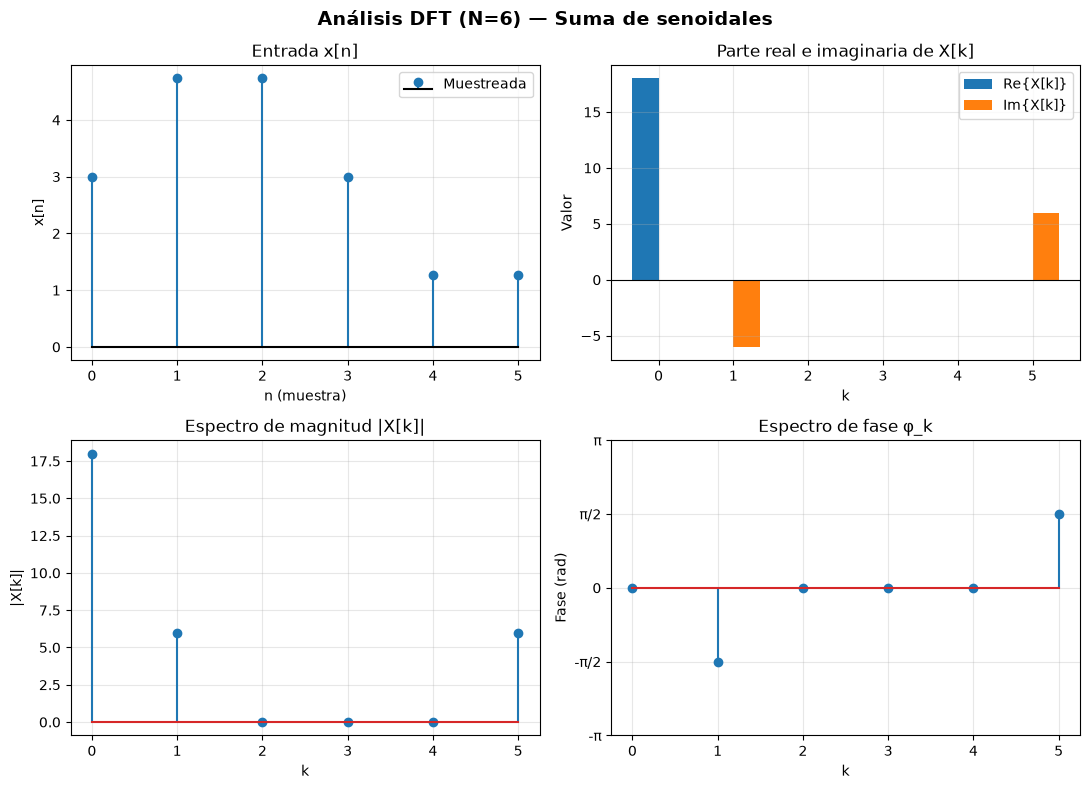

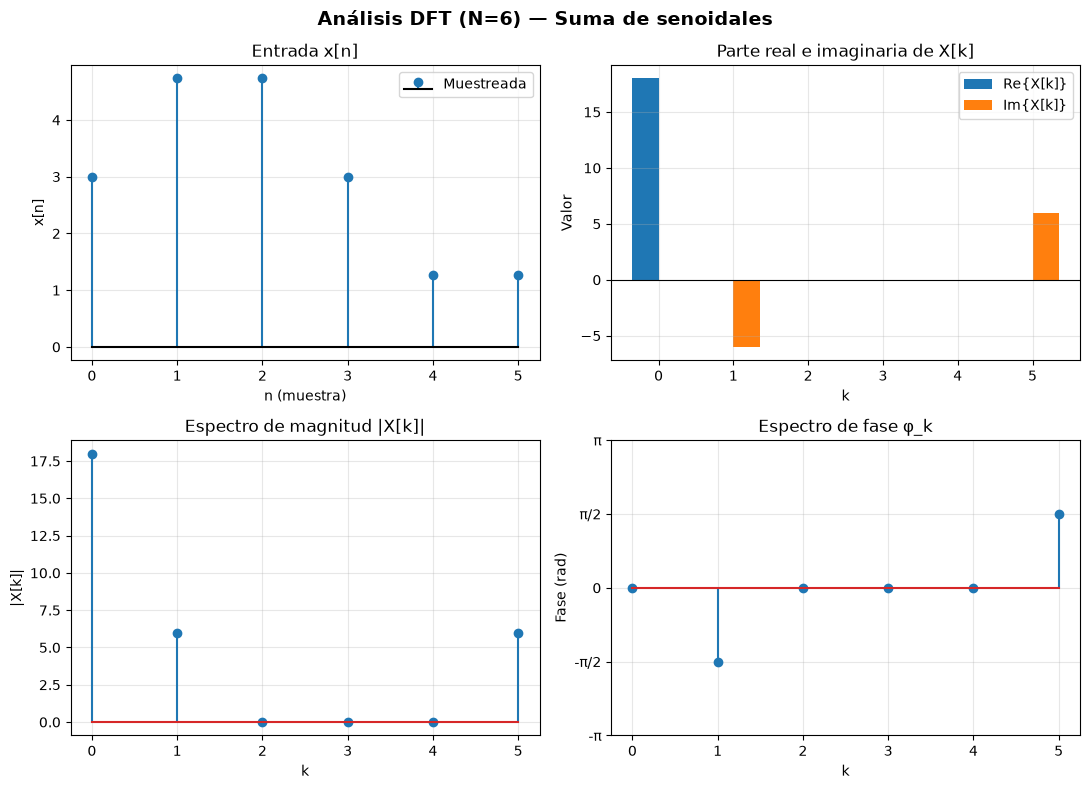

In [63]:
imprimir_resultados(fdots, "Suma de senoidales")
graficar_dft(fdots, titulo="Suma de senoidales")